<a href="https://colab.research.google.com/github/SMTorg/smt/blob/master/tutorial/PCE/SMT_PCE_tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Polynomial Chaos Expansion (PCE & SparsePCE) in SMT

This tutorial demonstrates Uncertainty Quantification (UQ), sensitivity analysis, arbitrary/empirical marginals, conditional expectation, and pure-JAX differentiable inference with **`PCE`**, **`SparsePCE`**, **`Sobol`**, and **`Halton`** in the Surrogate Modeling Toolbox (SMT).

**Cite us:**
- M.-A. Bouhlel, J. T. Hwang, N. Bartoli, R. Lafage, J. Morlier, J. R. R. A. Martins (2019), *A Python surrogate modeling framework with derivatives*, Advances in Engineering Software, 102662.
- P. Saves, R. Lafage, N. Bartoli, Y. Diouane, J. Bussemaker, T. Lefebvre, J. T. Hwang, J. Morlier, J. R. R. A. Martins (2024), *SMT 2.0: A Surrogate Modeling Toolbox with a focus on hierarchical and mixed variables Gaussian processes*, Advances in Engineering Software, 188, 103571.

In [1]:
# %pip install smt
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as st

from smt.sampling_methods import LHS, Halton, Sobol
from smt.surrogate_models import PCE, SparsePCE

## 1. Quasi-Monte Carlo Sampling (`Sobol` & `Halton` vs `LHS`)

SMT provides Owen-scrambled `Sobol` and `Halton` sequences via the unified `SamplingMethod` API, which can also be called directly from `PCE.sample_design(n_samples, sampling=...)`.

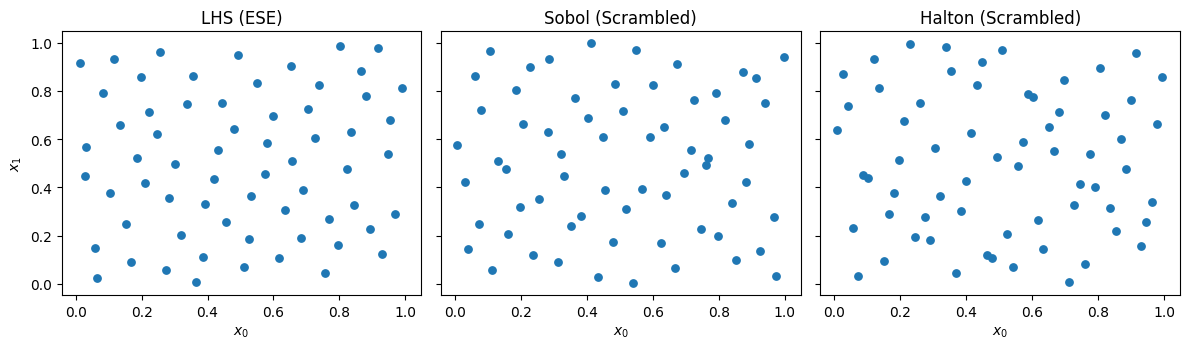

In [2]:
xlimits = np.array([[0.0, 1.0], [0.0, 1.0]])
n_pts = 64
x_lhs = LHS(xlimits=xlimits, criterion="ese", seed=42)(n_pts)
x_sob = Sobol(xlimits=xlimits, seed=42)(n_pts)
x_hal = Halton(xlimits=xlimits, seed=42)(n_pts)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True, sharey=True)
for ax, pts, title in zip(
    axes,
    [x_lhs, x_sob, x_hal],
    ["LHS (ESE)", "Sobol (Scrambled)", "Halton (Scrambled)"],
):
    ax.scatter(pts[:, 0], pts[:, 1], s=28)
    ax.set_title(title)
    ax.set_xlabel("$x_0$")
axes[0].set_ylabel("$x_1$")
plt.tight_layout()
plt.show()

## 2. Full `PCE`: Gauss Quadrature vs OLS & Christoffel WLS (`weights='christoffel'`)

On smooth low-dimensional problems with independent marginals, tensor-product Gauss quadrature (`quadrature_points()`) achieves spectral accuracy, while inverse Christoffel weighting (`weights='christoffel'`) improves stability for regression on non-uniform or random designs.

Max abs error - Quadrature: 2.95e-04
Max abs error - OLS:        1.90e-03
Max abs error - Christoffel: 2.22e-03


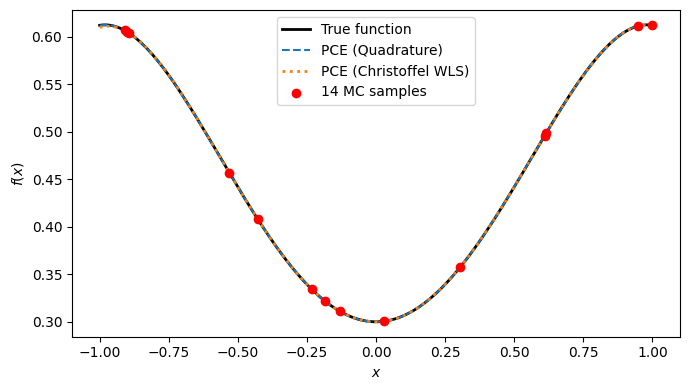

In [3]:
def fun_1d(x):
    return x * np.sin(2.0 * x) + 0.3 * np.cos(3.0 * x)


xlim_1d = np.array([[-1.0, 1.0]])

sm_q = PCE(degree=7, xlimits=xlim_1d, method="quadrature", print_global=False)
xq, wq = sm_q.quadrature_points(order=8)
sm_q.options["weights"] = wq
sm_q.set_training_values(xq, fun_1d(xq))
sm_q.train()

x_reg = sm_q.sample_design(14, sampling="mc", seed=5)
sm_ols = PCE(degree=7, xlimits=xlim_1d, method="ols", print_global=False)
sm_ols.set_training_values(x_reg, fun_1d(x_reg))
sm_ols.train()

sm_cw = PCE(
    degree=7, xlimits=xlim_1d, method="ols", weights="christoffel", print_global=False
)
sm_cw.set_training_values(x_reg, fun_1d(x_reg))
sm_cw.train()

xg = np.linspace(-1.0, 1.0, 200).reshape(-1, 1)
yt = fun_1d(xg).ravel()
print(
    "Max abs error - Quadrature:",
    f"{np.max(np.abs(sm_q.predict_values(xg).ravel() - yt)):.2e}",
)
print(
    "Max abs error - OLS:       ",
    f"{np.max(np.abs(sm_ols.predict_values(xg).ravel() - yt)):.2e}",
)
print(
    "Max abs error - Christoffel:",
    f"{np.max(np.abs(sm_cw.predict_values(xg).ravel() - yt)):.2e}",
)

plt.figure(figsize=(7, 4))
plt.plot(xg, yt, "k-", lw=2, label="True function")
plt.plot(xg, sm_q.predict_values(xg), "--", label="PCE (Quadrature)")
plt.plot(xg, sm_cw.predict_values(xg), ":", lw=2, label="PCE (Christoffel WLS)")
plt.scatter(x_reg, fun_1d(x_reg), color="red", zorder=5, label="14 MC samples")
plt.legend()
plt.xlabel("$x$")
plt.ylabel("$f(x)$")
plt.tight_layout()
plt.show()

## 3. Adaptive `SparsePCE` on the 3D Ishigami Benchmark

`SparsePCE` combines hyperbolic $q$-norm truncation with forward basis selection (`lars`, `omp`, `lasso`, `sp`, `bcs`) scored via Blatman-Sudret analytical Modified Leave-One-Out (MLOO).

LARS | deg=8, q=1.0, active=19/165, Q2_LOO=0.999669, val_RMSE=0.0862


 OMP | deg=8, q=1.0, active=59/165, Q2_LOO=0.999946, val_RMSE=0.1338


  SP | deg=8, q=1.0, active=26/165, Q2_LOO=0.999814, val_RMSE=0.1372


 BCS | deg=8, q=1.0, active=64/165, Q2_LOO=0.999958, val_RMSE=0.1549


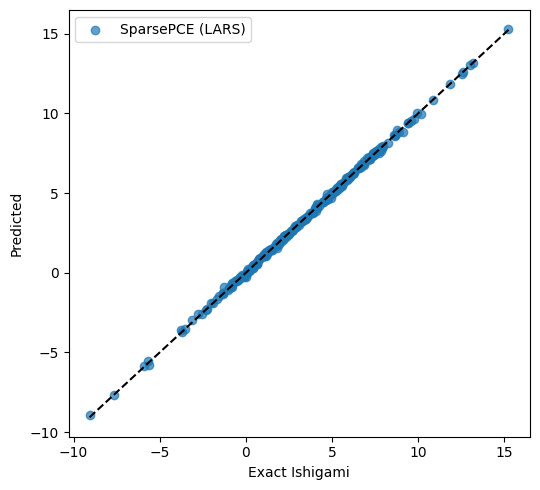

In [4]:
def ishigami(x):
    return (
        np.sin(x[:, 0])
        + 7.0 * np.sin(x[:, 1]) ** 2
        + 0.1 * (x[:, 2] ** 4) * np.sin(x[:, 0])
    )[:, None]


xlimits = np.array([[-np.pi, np.pi]] * 3)
tpl = SparsePCE(xlimits=xlimits, print_global=False)
xt = tpl.sample_design(128, sampling="sobol", seed=7)
yt = ishigami(xt)
x_val = tpl.sample_design(250, sampling="halton", seed=19)
y_val = ishigami(x_val).ravel()

models = {}
for solver in ("lars", "omp", "sp", "bcs"):
    m = SparsePCE(
        xlimits=xlimits,
        degree=range(2, 9),
        q_norm=[1.0, 0.75],
        method=solver,
        print_global=False,
    )
    m.set_training_values(xt, yt)
    m.train()
    models[solver] = m
    rmse = np.sqrt(np.mean((m.predict_values(x_val).ravel() - y_val) ** 2))
    print(
        f"{solver.upper():>4} | deg={m.degree_}, q={m.q_norm_}, "
        f"active={m.multi_indices.shape[0]}/{m.n_basis_candidate_}, "
        f"Q2_LOO={float(m.q2_loo_[0]):.6f}, val_RMSE={rmse:.4f}"
    )

plt.figure(figsize=(5.5, 5))
yp = models["lars"].predict_values(x_val).ravel()
plt.scatter(y_val, yp, alpha=0.7, label="SparsePCE (LARS)")
lims = [min(y_val.min(), yp.min()), max(y_val.max(), yp.max())]
plt.plot(lims, lims, "k--")
plt.xlabel("Exact Ishigami")
plt.ylabel("Predicted")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Analytical UQ Moments & Global Sensitivity Analysis (Sobol Indices)

Orthonormal PCE expansions give exact closed-form `mean()`, `variance()`, `std()`, `skewness()`, `kurtosis()`, and `sobol_indices(second_order=True)` / `subset_sobol()` directly from the trained coefficients.

PCE moments: {'mean': array([3.4929]), 'variance': array([13.7733]), 'std': array([3.7112]), 'skewness': array([0.009]), 'kurtosis': array([0.4907])}
Exact mean=3.5000, Exact var=13.8446
S1 (PCE vs Exact): [0.3151 0.4455 0.    ] vs [0.3139 0.4424 0.    ]
ST (PCE vs Exact): [0.5545 0.4457 0.2394] vs [0.5576 0.4424 0.2437]
S_{0,2} closed subset Sobol: 0.5543 vs exact: 0.5576


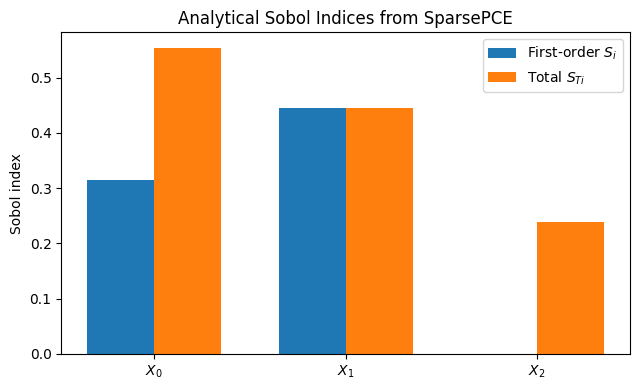

In [5]:
sm_ishi = models["lars"]
mom = sm_ishi.moments()
sobol = sm_ishi.sobol_indices(second_order=True)

exact_mean = 3.5
exact_var = (
    0.5 + 49.0 / 8.0 + (0.1 * np.pi**4 / 5.0 + (0.01 * np.pi**8) / 18.0 + 0.5 - 0.5)
)
# Standard Ishigami analytical moments and Sobol indices (a=7, b=0.1)
v1 = 0.5 * (1.0 + 0.1 * np.pi**4 / 5.0) ** 2
v2 = 49.0 / 8.0
v13 = (0.01 * np.pi**8) * (1.0 / 18.0 - 1.0 / 50.0)
v_tot = v1 + v2 + v13

print("PCE moments:", {k: np.round(v, 4) for k, v in mom.items()})
print(f"Exact mean={exact_mean:.4f}, Exact var={v_tot:.4f}")
print(
    "S1 (PCE vs Exact):",
    np.round(sobol["first_order"], 4),
    "vs",
    np.round([v1 / v_tot, v2 / v_tot, 0.0], 4),
)
print(
    "ST (PCE vs Exact):",
    np.round(sobol["total"], 4),
    "vs",
    np.round([(v1 + v13) / v_tot, v2 / v_tot, v13 / v_tot], 4),
)
print(
    "S_{0,2} closed subset Sobol:",
    f"{sm_ishi.subset_sobol([0, 2], closed=True):.4f}",
    "vs exact:",
    f"{(v1 + v13) / v_tot:.4f}",
)

idx = np.arange(3)
w = 0.35
plt.figure(figsize=(6.5, 4))
plt.bar(idx - w / 2, sobol["first_order"], width=w, label="First-order $S_i$")
plt.bar(idx + w / 2, sobol["total"], width=w, label="Total $S_{Ti}$")
plt.xticks(idx, ["$X_0$", "$X_1$", "$X_2$"])
plt.ylabel("Sobol index")
plt.title("Analytical Sobol Indices from SparsePCE")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Non-Askey Stieltjes & Data-Driven Empirical (aPCE) Marginals

Beyond standard Askey families (`uniform`, `normal`, `gamma`/`exponential`, `beta`), SMT supports discretized Stieltjes polynomials on arbitrary SciPy distributions (`('stieltjes', scipy_rv)`) and data-driven arbitrary PCE (`{'type': 'empirical', 'data': samples}`), keeping polynomials orthogonal in physical coordinates.

In [6]:
rv_ln = st.lognorm(s=0.4)
rng = np.random.default_rng(77)
emp_samples = rng.weibull(2.2, size=150)

sm_arb = PCE(
    distributions=[("stieltjes", rv_ln), {"type": "empirical", "data": emp_samples}],
    degree=3,
    method="quadrature",
    print_global=False,
)
xq_a, wq_a = sm_arb.quadrature_points(order=5)
y_a = (2.0 * xq_a[:, 0] + 0.5 * xq_a[:, 1] ** 2)[:, None]
sm_arb.options["weights"] = wq_a
sm_arb.set_training_values(xq_a, y_a)
sm_arb.train()

exact_mu = 2.0 * rv_ln.mean() + 0.5 * float(np.mean(emp_samples**2))
print(f"PCE mean: {float(sm_arb.mean()[0]):.10f} | Exact mixture mean: {exact_mu:.10f}")
print(
    "Sobol indices [lognorm X0, empirical X1]:",
    np.round(sm_arb.sobol_indices()["first_order"], 6),
)

PCE mean: 2.6869969723 | Exact mixture mean: 2.6869969723
Sobol indices [lognorm X0, empirical X1]: [0.777379 0.222621]


## 6. Analytical `conditional_expectation()` & Pure-JAX Differentiable Inference

`conditional_expectation(indices)` analytically integrates out complementary variables, returning a live reduced `PCE` whose variance satisfies the Law of Total Variance. `get_jax_predictor()` compiles any trained affine PCE (including `stieltjes` / `empirical`) into a pure-JAX differentiable callable.

Law of total variance E[Var]/Var: 0.315086 vs S1[0]=0.315086


Max |JAX grad - CPU predict_derivatives|: 3.55e-15


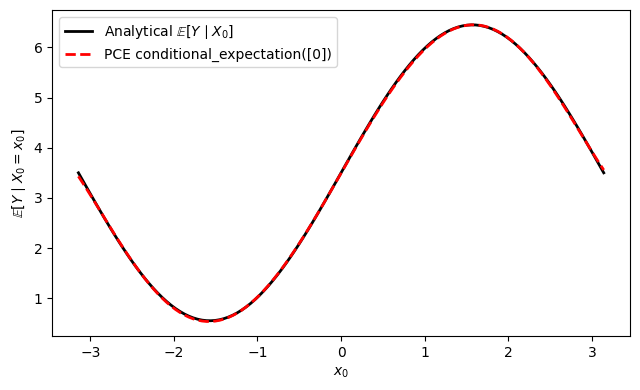

In [7]:
cond_0 = sm_ishi.conditional_expectation([0])
print(
    "Law of total variance E[Var]/Var:",
    f"{float(cond_0.variance()[0] / sm_ishi.variance()[0]):.6f} vs S1[0]={float(sobol['first_order'][0]):.6f}",
)

x0_grid = np.linspace(-np.pi, np.pi, 120).reshape(-1, 1)
exact_cond0 = 3.5 + (1.0 + 0.1 * np.pi**4 / 5.0) * np.sin(x0_grid)

try:
    import jax
    import jax.numpy as jnp

    predict_jax = jax.jit(sm_arb.get_jax_predictor())
    x_probe = jnp.array([[1.2, 0.9], [0.7, 1.4]])
    grad_fn = jax.vmap(jax.grad(lambda z: predict_jax(z[None, :])[0, 0]))
    jax_dy = np.asarray(grad_fn(x_probe))[:, 0:1]
    cpu_dy = sm_arb.predict_derivatives(np.asarray(x_probe), kx=0)
    print(
        "Max |JAX grad - CPU predict_derivatives|:",
        f"{np.max(np.abs(jax_dy - cpu_dy)):.2e}",
    )
except ImportError:
    print("JAX not installed; skipping get_jax_predictor() demo.")

plt.figure(figsize=(6.5, 4))
plt.plot(
    x0_grid, exact_cond0, "k-", lw=2, label="Analytical $\\mathbb{E}[Y \\mid X_0]$"
)
plt.plot(
    x0_grid,
    cond_0.predict_values(x0_grid),
    "r--",
    lw=2,
    label="PCE conditional_expectation([0])",
)
plt.xlabel("$x_0$")
plt.ylabel("$\\mathbb{E}[Y \\mid X_0 = x_0]$")
plt.legend()
plt.tight_layout()
plt.show()